# String art calculé — carnet d'exploration

Ce carnet retrace, dans l'ordre où elles ont été faites, les expériences qui ont conduit au
code de `stringart_claude` : ce qui a été essayé, ce qui a échoué, ce qui a marché, et
pourquoi. Il se termine par la partie pratique : calculer sa propre pièce.

**Le problème.** Une toile ronde, des clous régulièrement espacés sur son pourtour, un fil
noir. On cherche dans quel ordre passer le fil d'un clou à l'autre pour que la toile, vue de
loin, ressemble à une image donnée. Le gris ne vient pas de la couleur du fil mais de la
**densité des passages**.

**Plan.**

1. Les images de travail
2. Un juge qu'on peut croire — et le premier échec
3. Un modèle du fil : trois candidats, un seul survit
4. Le moteur : évaluer 26 000 cordes sans les recalculer
5. Les méthodes de résolution, de la plus naïve à la plus fine
6. Le banc d'essai
7. Ce qui change vraiment le résultat (et ce qui ne change rien)
8. **À vous : calculer une pièce**
9. Bilan

Le carnet est un fichier `.py` à cellules `# %%` (il se relit et se compare comme du code) ;
`exploration.ipynb` en est la version exécutée, avec ses images. Pour le régénérer :
`uv run jupytext --to ipynb --execute notebooks/exploration.py`.

In [1]:
import io
import sys
import time
from pathlib import Path

import matplotlib

EN_CARNET = "ipykernel" in sys.modules
if not EN_CARNET:
    matplotlib.use("Agg")  # exécuté comme simple script : pas de fenêtre à ouvrir

import matplotlib.pyplot as plt
import numpy as np
from matplotlib import font_manager
from PIL import Image, ImageDraw, ImageFont

from stringart_claude import (
    GAMMA,
    SOLVEURS,
    Probleme,
    Toile,
    banc,
    charger_image,
    comparer,
    creer,
    geometrie,
    image_modele,
    longueur_fil_m,
    planche,
    preparer_cible,
    rendu_physique,
    resoudre,
    solveurs,
    texte_sequence,
)
from stringart_claude.moteur import _gains_complets

# Le dossier du dépôt, que le carnet soit lancé depuis la racine ou depuis notebooks/.
RACINE = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "images").is_dir())
IMAGES = RACINE / "images"


# La police par défaut de Pillow n'a pas les lettres accentuées ; celle de matplotlib, si.
POLICE = font_manager.findfont("DejaVu Sans")


def montrer(images, titres=None, taille=250):
    """Affiche des images côte à côte, chacune sous son titre."""
    feuille = planche(list(images), taille=taille, marge=6)
    if titres:
        haut = 24
        avec_titres = Image.new("L", (feuille.width, feuille.height + haut), 255)
        avec_titres.paste(feuille, (0, haut))
        police = ImageFont.truetype(POLICE, 14)
        dessin = ImageDraw.Draw(avec_titres)
        for i, titre in enumerate(titres):
            dessin.text((6 + i * (taille + 6) + taille / 2, 5), titre, fill=0, font=police,
                        anchor="ma")  # fmt: skip
        feuille = avec_titres
    if EN_CARNET:
        from IPython.display import Image as ImageCarnet
        from IPython.display import display

        tampon = io.BytesIO()
        feuille.save(tampon, "JPEG", quality=88)
        display(ImageCarnet(data=tampon.getvalue()))


def tracer(figure):
    """Affiche une figure matplotlib (ou la referme, hors carnet)."""
    figure.tight_layout()
    if EN_CARNET:
        plt.show()
    plt.close(figure)


def dire(texte):
    """Affiche du Markdown dans le carnet, du texte brut ailleurs."""
    if EN_CARNET:
        from IPython.display import Markdown, display

        display(Markdown(texte))
    else:
        print(texte)


def simuler(toile, sequence, taille=500):
    """La pièce simulée, calculée en grand pour un affichage propre."""
    return rendu_physique(toile, sequence, taille=taille)

## 1. Les images de travail

La toile de référence du carnet : **50 cm de diamètre, 240 clous, fil de 0,2 mm**, calculée
sur une grille de 300 × 300 pixels. Un pixel y mesure 1,7 mm : huit fois la largeur du fil.

Quatre images, choisies pour ne pas se ressembler :

- `portrait` — un visage en gros plan (portrait officiel d'une astronaute de la NASA, domaine
  public). C'est le sujet classique du string art, et le plus exigeant : on sait
  immédiatement si un visage est raté.
- `chat` — une photo ordinaire, sujet clair sur fond sombre.
- `arbre` — la photo d'une vraie pièce de string art. C'est le **témoin** : une image qu'on
  sait réalisable avec du fil, puisqu'elle en est déjà faite.
- `elephant` — un dessin très clair, presque sans noirs : le cas difficile.

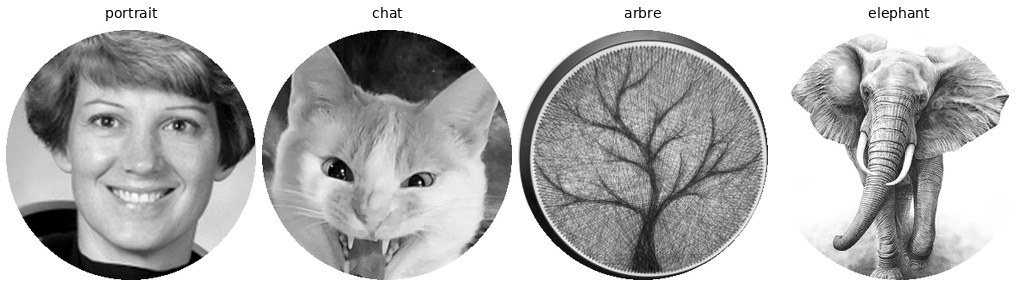

240 clous → 26520 cordes possibles ; un fil couvre 12 % d'un pixel qu'il traverse.


In [2]:
TOILE = Toile(diametre_mm=500, n_clous=240, epaisseur_fil_mm=0.2, cote=300)
GEO = geometrie(TOILE)

SOURCES = {
    "portrait": (
        charger_image(IMAGES / "portrait.png"),
        {"zoom": 1.55, "decalage": (-0.01, 0.02), "relief": 0.03},
    ),
    "chat": (
        charger_image(IMAGES / "chat.jpg"),
        {"zoom": 1.25, "decalage": (0.0, -0.08), "relief": 0.01},
    ),
    "arbre": (charger_image(IMAGES / "arbre.png"), {"contraste": "auto"}),
    "elephant": (charger_image(IMAGES / "elephant.png"), {}),
}
# Les cibles « brutes » : l'image simplement cadrée dans le disque, tons d'origine.
BRUTES = {
    nom: preparer_cible(image, TOILE.cote, contraste="aucun", noir=0.0,
                        **{k: v for k, v in reglages.items() if k in ("zoom", "decalage")})
    for nom, (image, reglages) in SOURCES.items()
}  # fmt: skip
# Les cibles de travail : cadrage et mise en tons propres à chaque image (justifiés en section 7).
CIBLES = {
    nom: preparer_cible(image, TOILE.cote, **reglages) for nom, (image, reglages) in SOURCES.items()
}
PROBLEMES = {nom: Probleme(GEO, cible) for nom, cible in CIBLES.items()}

montrer(BRUTES.values(), BRUTES.keys())
print(f"{TOILE.n_clous} clous → {GEO.n_cordes} cordes possibles ; un fil couvre "
      f"{100 * TOILE.alpha:.0f} % d'un pixel qu'il traverse.")  # fmt: skip

Une **corde** est un segment de fil tendu entre deux clous. On écarte les cordes entre clous
trop voisins (moins de 10 clous d'écart ici) : elles sont minuscules, collées au bord, et
n'apportent rien à l'image. Il en reste 26 520, et tout le problème est de choisir lesquelles
poser.

## 2. Un juge qu'on peut croire — et le premier échec

Avant d'optimiser quoi que ce soit, il faut savoir **noter un résultat**, et le noter
indépendamment de la méthode qui l'a produit : un solveur qui se note lui-même avec son propre
modèle a toujours raison.

Le juge est donc une **simulation de la pièce réelle** (`rendu_physique`) : chaque fil y est un
trait noir opaque, de sa vraie largeur, dessiné sur une image de 7 500 pixels de côté où il fait
trois pixels de large. On réduit ensuite cette image en moyennant la lumière, comme le fait
l'œil qui recule.

### Échec n° 1 : faire confiance au premier outil venu

La première version de ce juge dessinait les fils avec `ImageDraw.line` de Pillow. Un contrôle
élémentaire l'a condamnée : **un fil seul doit cacher une surface égale à sa longueur × sa
largeur**, quelle que soit son orientation.

In [3]:
from stringart_claude.toile import positions_clous


def encre_pillow(a, b, cote=5000, largeur=2):
    """Surface noircie par Pillow pour un trait de `largeur` px entre les clous a et b."""
    points = positions_clous(TOILE.n_clous, cote)[[a, b]] - 0.5
    dessin = Image.new("L", (cote, cote), 255)
    ImageDraw.Draw(dessin).line([(c, r) for r, c in points], fill=0, width=largeur)
    longueur = float(np.hypot(*(points[1] - points[0])))
    return float((np.asarray(dessin) == 0).sum()) / (longueur * largeur)


def encre_simulation(a, b):
    """Même mesure pour le rendu physique du projet (en lumière, sans codage perceptuel)."""
    lumiere = rendu_physique(TOILE, [a, b], gamma=1.0)
    k = GEO.id_corde[a, b]
    return float((1.0 - lumiere).sum()) / (TOILE.alpha * GEO.longueur_mm[k] / TOILE.pas_mm)


lignes = [
    "| corde | surface Pillow / surface vraie | simulation du projet / vraie |",
    "|---|---:|---:|",
]
for a, b in [(0, 110), (0, 120), (30, 150), (60, 85), (116, 161), (20, 200)]:
    lignes.append(f"| {a} → {b} | {encre_pillow(a, b):.2f} | {encre_simulation(a, b):.2f} |")
dire("\n".join(lignes))

| corde | surface Pillow / surface vraie | simulation du projet / vraie |
|---|---:|---:|
| 0 → 110 | 0.99 | 1.00 |
| 0 → 120 | 1.00 | 1.00 |
| 30 → 150 | 1.06 | 1.00 |
| 60 → 85 | 0.95 | 1.00 |
| 116 → 161 | 0.68 | 1.00 |
| 20 → 200 | 0.61 | 1.00 |

Selon l'orientation du trait, Pillow noircit de 61 % à 106 % de la surface attendue : ses
traits épais de deux pixels ne font pas deux pixels dans toutes les directions. Un juge qui se
trompe d'un tiers sur la quantité de fil ne juge rien.

La version retenue calcule elle-même la surface couverte, pixel par pixel, fractions de pixel
comprises sur les bords du fil. Elle retrouve la surface exacte à 1 % près dans toutes les
directions.

**Leçon.** Vérifier l'instrument de mesure sur un cas dont on connaît la réponse, avant de
s'en servir pour départager quoi que ce soit.

### Les notes du juge

La simulation est comparée à la cible par trois notes (`evaluation.py`) :

- **EQM** : l'écart quadratique moyen brut. Sévère avec le grain du fil.
- **EQM floue** : le même après un léger flou des deux images — « est-ce que les tons sont
  justes, vu de quelques pas ».
- **SSIM** : similarité de structure (1 = identique), sensible aux contours.

Aucune ne remplace l'œil : le carnet montre toujours les images à côté des chiffres.

## 3. Un modèle du fil : trois candidats, un seul survit

Simuler la pièce coûte un dixième de seconde. C'est trop pour un solveur qui doit évaluer des
millions de coups : il lui faut un **modèle** rapide de ce que fait un fil. Tout le reste en
dépend, donc on le valide contre la simulation avant d'aller plus loin.

Le fil est bien plus fin qu'un pixel de travail. Une corde `k` qui traverse le pixel `p` en
cache une fraction `c[p, k]` = longueur traversée × largeur du fil ÷ surface du pixel. Reste à
dire comment ces fractions se **combinent** quand plusieurs fils passent dans le même pixel.

- **Candidat A — addition écrêtée.** Les couvertures s'ajoutent, et on plafonne à 1 :
  `noirceur = min(1, Σ c)`. C'est le modèle le plus répandu.
- **Candidat B — produit.** Deux fils qui se croisent se recouvrent en partie. Si chacun laisse
  voir une part `1 − c` du pixel, ensemble ils laissent voir le *produit* de ces parts :
  `lumière = ∏ (1 − c)`. C'est une loi de Beer-Lambert.

On les compare sur une vraie solution (un glouton, pour avoir une toile remplie de façon
réaliste), contre la simulation.

2519 cordes posées
A, addition écrêtée : écart à la simulation 0.212, biais -0.182
B, produit          : écart à la simulation 0.045, biais -0.000


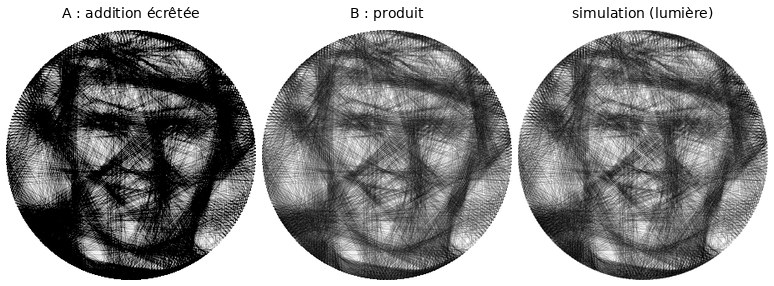

In [4]:
essai = solveurs.glouton_sequentiel(PROBLEMES["portrait"], saut_bord=False)
present = np.zeros(GEO.n_cordes)
present[essai.cordes] = 1.0

couverture = GEO.matrice_couverture()  # c[p, k], matrice creuse pixels × cordes
log_visible = couverture.copy()
log_visible.data = np.log1p(-log_visible.data)

forme = (TOILE.cote, TOILE.cote)
lumiere_a = 1.0 - np.minimum(1.0, couverture @ present).reshape(forme)
lumiere_b = np.exp(log_visible @ present).reshape(forme)
lumiere_vraie = rendu_physique(TOILE, essai.sequence, gamma=1.0)


def ecart(a, b):
    return float(np.sqrt(np.mean((a - b)[GEO.masque] ** 2)))


print(f"{essai.n_cordes} cordes posées")
print(f"A, addition écrêtée : écart à la simulation {ecart(lumiere_a, lumiere_vraie):.3f}, "
      f"biais {np.mean((lumiere_a - lumiere_vraie)[GEO.masque]):+.3f}")  # fmt: skip
print(f"B, produit          : écart à la simulation {ecart(lumiere_b, lumiere_vraie):.3f}, "
      f"biais {np.mean((lumiere_b - lumiere_vraie)[GEO.masque]):+.3f}")  # fmt: skip
montrer(
    [lumiere_a, lumiere_b, lumiere_vraie],
    ["A : addition écrêtée", "B : produit", "simulation (lumière)"],
)

**Échec n° 2 : l'addition écrêtée.** Elle prédit une toile bien plus noire que la simulation
(biais fortement négatif) : elle compte comme entièrement cachée une surface que les fils, en
se chevauchant, ne cachent qu'une fois. Un solveur bâti dessus croit avoir atteint le noir
dès le huitième fil, s'arrête, et la vraie pièce sort pâle.

Le produit, lui, colle à la simulation sans biais. L'écart qui reste est du **grain** : la
position exacte de chaque fil dans son pixel, que le modèle ne connaît qu'en moyenne.

### Échec n° 3 : oublier que l'œil n'est pas linéaire

Les trois images ci-dessus sont des quantités de **lumière**. Or une image ordinaire ne stocke
pas de la lumière : elle stocke des valeurs *perçues*. Un pixel de valeur 0,5 — le gris moyen —
ne renvoie que 22 % de la lumière du blanc (`0,5 ** 2,2`). Comparer directement la lumière de
la toile aux valeurs de l'image, c'est demander beaucoup trop peu de fil.

On fait l'expérience : même solveur, même image, avec et sans cette conversion. Les deux
pièces sont ensuite simulées et montrées telles qu'on les verrait.

sans conversion : 1208 cordes, EQM floue 0.179, SSIM 0.29


avec conversion : 2557 cordes, EQM floue 0.072, SSIM 0.32


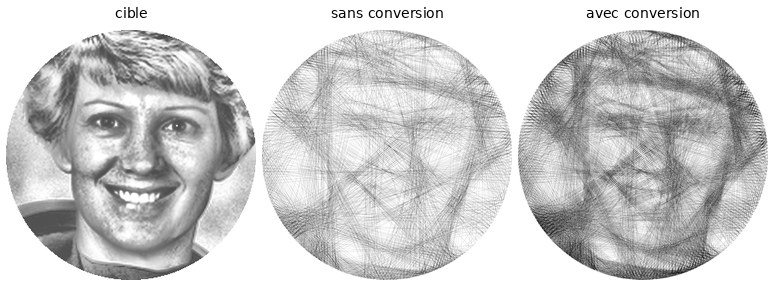

In [5]:
cible = CIBLES["portrait"]
naif = resoudre(Probleme(geometrie(TOILE, gamma=1.0), cible))  # lumière = valeur perçue (faux)
juste = resoudre(PROBLEMES["portrait"])  # lumière ** (1 / 2.2) = valeur perçue

for nom, resultat in [("sans conversion", naif), ("avec conversion", juste)]:
    notes = comparer(cible, rendu_physique(TOILE, resultat.sequence))
    print(f"{nom} : {resultat.n_cordes} cordes, EQM floue {notes.eqm_floue:.3f}, "
          f"SSIM {notes.ssim:.2f}")  # fmt: skip
montrer(
    [cible, simuler(TOILE, naif.sequence), simuler(TOILE, juste.sequence)],
    ["cible", "sans conversion", "avec conversion"],
)

Sans la conversion, le solveur pose moitié moins de fil et la pièce sort délavée : il a visé
juste en lumière et faux en perception.

La bonne nouvelle est que la correction est **gratuite**. La valeur perçue d'un pixel vaut
`(∏ (1 − c)) ** (1/2,2)`, c'est-à-dire `∏ (1 − c) ** (1/2,2)` : il suffit d'élever une fois
pour toutes les coefficients de la matrice à la puissance 1/2,2, et le modèle reste un simple
produit. C'est le **modèle retenu** — candidat C, un produit en valeurs perçues :

$$T_p \;=\; \prod_{k \in S} q_{pk}, \qquad q_{pk} = (1 - c_{pk})^{1/2{,}2}$$

et l'**objectif** que tous les solveurs minimisent est l'écart quadratique moyen entre `T` et
l'image cible `L`, sur le disque :

$$\text{coût}(S) \;=\; \sum_p w_p\,(T_p - L_p)^2$$

Conséquence pratique, qui explique les habitudes du métier : chaque fil n'assombrit la
perception que de 5 % environ. Il en faut **des milliers**.

## 4. Le moteur : évaluer 26 000 cordes sans les recalculer

Tous les solveurs posent la même question, des milliers de fois : *« de combien l'objectif
varierait-il si je posais (ou retirais) cette corde ? »* On appelle cette variation le **gain**
de la corde.

Poser une corde ne modifie que les quelques centaines de pixels qu'elle traverse. Le moteur
(`moteur.py`) en tire parti : il tient à jour le gain de **toutes** les cordes en permanence.
Quand une corde bascule, il ne corrige que les gains des cordes qui croisent ses pixels. Choisir
le meilleur coup parmi 26 520 devient alors une simple recherche de minimum dans un tableau.

Le produit s'y prête bien : retirer une corde, c'est diviser par ce qu'on avait multiplié. Les
retraits coûtent donc exactement le même prix que les poses — ce qui ouvre la porte aux
méthodes qui reviennent sur leurs choix.

In [6]:
pb = PROBLEMES["portrait"]
etat = pb.etat(juste.cordes)

debut = time.perf_counter()
for _ in range(5):
    complet = _gains_complets(etat.transmission, pb.cible_plat, pb.poids_plat, etat.presente,
                              GEO.c_ptr, GEO.c_pix, GEO.c_q, 0.0)  # fmt: skip
t_complet = (time.perf_counter() - debut) / 5

hasard = np.random.default_rng(0)
coups = hasard.integers(0, GEO.n_cordes, 2000)
debut = time.perf_counter()
for k in coups:
    etat.basculer(int(k))
t_bascule = (time.perf_counter() - debut) / len(coups)

reference = _gains_complets(etat.transmission, pb.cible_plat, pb.poids_plat, etat.presente,
                            GEO.c_ptr, GEO.c_pix, GEO.c_q, 0.0)  # fmt: skip
print(f"recalculer tous les gains : {1000 * t_complet:.1f} ms")
print(f"basculer une corde et corriger les gains touchés : {1000 * t_bascule:.2f} ms")
print(f"écart maximal entre gains tenus à jour et gains recalculés, après {len(coups)} bascules : "
      f"{np.abs(reference - etat.gain).max():.1e} (gains de l'ordre de {np.abs(reference).mean():.1e})")  # fmt: skip

recalculer tous les gains : 29.1 ms
basculer une corde et corriger les gains touchés : 0.29 ms
écart maximal entre gains tenus à jour et gains recalculés, après 2000 bascules : 3.2e-19 (gains de l'ordre de 2.7e-05)


Un coup coûte une fraction de milliseconde, et les gains tenus à jour restent exacts à la
précision de la machine. Une résolution complète — quelques milliers de coups — tient donc en
une seconde. C'est ce qui rend le banc d'essai praticable : toutes les méthodes ci-dessous
partagent ce moteur, ce modèle et cet objectif. **Seule la stratégie de recherche change.**

## 5. Les méthodes de résolution

### 5.1 Le tri naïf — échec n° 4, et le plus instructif

L'idée qui vient en premier : une corde est utile si elle traverse des zones sombres. On note
donc chaque corde par l'obscurité moyenne de l'image le long de son trajet, et on pose les
mieux notées.

toile vide : écart 0.386   →   tri naïf : écart 0.288 avec 2702 cordes


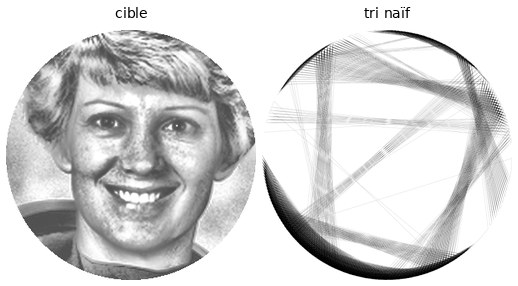

In [7]:
pb = PROBLEMES["portrait"]
cible = CIBLES["portrait"]
vide = pb.cout([])
r_naif = resoudre(pb, "tri_naif")
print(f"toile vide : écart {np.sqrt(vide):.3f}   →   tri naïf : écart {np.sqrt(r_naif.cout):.3f} "
      f"avec {r_naif.n_cordes} cordes")  # fmt: skip
montrer([cible, simuler(TOILE, r_naif.sequence)], ["cible", "tri naïf"])

Le résultat ne rattrape qu'**un quart de l'écart de la toile vide**, quand les méthodes qui
suivent le diviseront par trois — et l'image n'a aucun rapport avec la cible. Toutes les cordes
bien notées passent par les mêmes zones sombres et s'y entassent, sans qu'aucune sache que les
autres ont déjà fait le travail. C'est le défaut de la « rétroprojection non filtrée » en
tomographie.

**Leçon.** La valeur d'une corde dépend de celles qui sont déjà posées. Toute méthode sérieuse
doit réévaluer les cordes au fur et à mesure — c'est exactement ce que le moteur rend bon marché.

### 5.2 Le glouton séquentiel — la méthode historique

C'est l'algorithme qui a popularisé le string art calculé : le fil part d'un clou ; à chaque
pas on pose, parmi les cordes qui partent du clou courant, celle qui réduit le plus l'objectif,
et on recommence depuis son autre bout. Le fil est continu par construction.

Quand plus aucune corde utile ne part du clou courant, on **longe le bord** jusqu'au clou le
plus proche d'où il en repart une — un geste qui ne traverse pas la toile, donc gratuit pour
l'image.

glouton séquentiel : écart 0.1213, 2587 cordes, 28 sauts le long du bord, 0.6 s


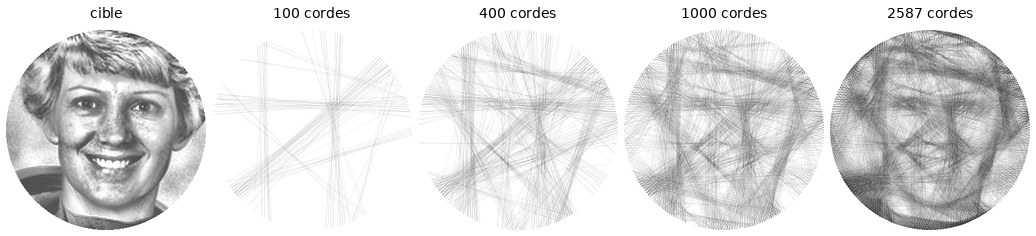

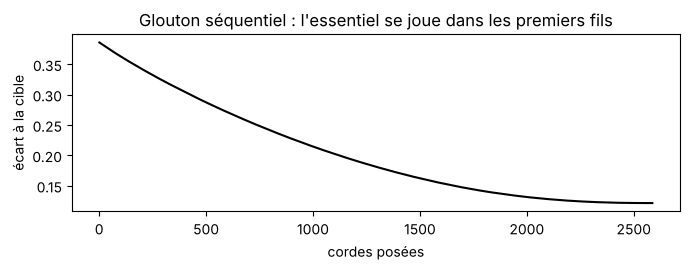

In [8]:
r_seq = resoudre(pb, "glouton_sequentiel")
print(f"glouton séquentiel : écart {np.sqrt(r_seq.cout):.4f}, {r_seq.n_cordes} cordes, "
      f"{r_seq.infos['sauts_de_bord']} sauts le long du bord, {r_seq.duree_s:.1f} s")  # fmt: skip

etapes = [100, 400, 1000, r_seq.n_cordes]
montrer(
    [cible] + [image_modele(GEO, r_seq.cordes_a(n)) for n in etapes],
    ["cible"] + [f"{n} cordes" for n in etapes],
    taille=200,
)

figure, axe = plt.subplots(figsize=(7, 2.8))
axe.plot(np.arange(1, len(r_seq.couts) + 1), np.sqrt(r_seq.couts), color="black")
axe.set_xlabel("cordes posées")
axe.set_ylabel("écart à la cible")
axe.set_title("Glouton séquentiel : l'essentiel se joue dans les premiers fils")
tracer(figure)

L'image se construit du plus sombre vers le plus subtil : les masses d'abord, les détails
ensuite. La courbe dit la même chose — les mille premières cordes font presque tout le travail,
les suivantes affinent. (Ces instantanés sont rejoués à partir du **journal** que tient chaque
solveur : la liste des cordes basculées, dans l'ordre. C'est la matière première du suivi en
temps réel prévu pour l'interface.)

### 5.3 Lever la contrainte du fil continu

Le glouton séquentiel ne choisit que parmi les ~220 cordes qui partent du clou courant. Or
**l'image finale ne dépend pas de l'ordre de pose** : seul compte l'ensemble des cordes. On
peut donc choisir librement la meilleure corde de *toute* la toile à chaque pas, puis chercher
après coup un parcours d'un seul tenant.

Ce parcours est un **chemin eulérien** dans le graphe dont les sommets sont les clous et les
arêtes les cordes. Il n'existe que si les clous ont (presque tous) un nombre pair de cordes ;
on rétablit la parité en reliant par le bord les clous « impairs » voisins (`sequence.py`).

In [9]:
r_glo = resoudre(pb, "glouton_global")
n_bord = len(r_glo.sequence) - 1 - r_glo.n_cordes
print(f"glouton global : écart {np.sqrt(r_glo.cout):.4f}, {r_glo.n_cordes} cordes, "
      f"{n_bord} pas de bord ajoutés pour relier le tout, {r_glo.duree_s:.1f} s")  # fmt: skip
print(
    f"gain sur l'objectif par rapport au séquentiel : {100 * (1 - r_glo.cout / r_seq.cout):.1f} %"
)

glouton global : écart 0.1206, 2558 cordes, 108 pas de bord ajoutés pour relier le tout, 0.5 s
gain sur l'objectif par rapport au séquentiel : 1.1 %


Le gain existe mais il est faible : **la contrainte du fil continu coûte environ un pour cent**.
Le glouton séquentiel n'était pas si mal loti — avec 240 clous, il y a presque toujours une bonne
corde à portée. En contrepartie, le parcours eulérien demande une centaine de pas de bord, soit
quelques pour cent de gestes en plus.

### 5.4 Avoir des remords : la recherche locale

Un glouton ne revient jamais sur ses choix. Or une corde posée au début, quand la toile était
vide, peut devenir nuisible une fois ses voisines en place. La **recherche locale** s'autorise,
à chaque pas, le meilleur coup parmi *poser ou retirer* une corde, et s'arrête quand plus aucun
coup isolé n'améliore l'objectif : c'est un optimum local.

In [10]:
r_loc = resoudre(pb, "recherche_locale")
n_retraits = (len(r_loc.journal) - r_loc.n_cordes) // 2
print(f"recherche locale : écart {np.sqrt(r_loc.cout):.4f}, {r_loc.n_cordes} cordes, "
      f"{n_retraits} cordes retirées en cours de route, {r_loc.duree_s:.1f} s")  # fmt: skip
print(f"gain sur l'objectif par rapport au glouton global : "
      f"{100 * (1 - r_loc.cout / r_glo.cout):.1f} %")  # fmt: skip

recherche locale : écart 0.1202, 2557 cordes, 167 cordes retirées en cours de route, 0.6 s
gain sur l'objectif par rapport au glouton global : 0.6 %


Une à deux centaines de cordes posées puis retirées, une amélioration d'un demi pour cent,
pour un temps de calcul inchangé. Modeste, mais gratuit : c'est la méthode **recommandée par
défaut**.

### 5.5 Sortir de l'optimum local : recuit simulé et recherche tabou

Un optimum local n'est pas l'optimum. Deux métaheuristiques classiques acceptent de dégrader
provisoirement la solution pour aller voir plus loin :

- le **recuit simulé** propose des bascules au hasard et accepte un mauvais coup avec une
  probabilité qui décroît à mesure que la « température » baisse ;
- la **recherche tabou** joue toujours le meilleur coup autorisé, même mauvais, et s'interdit
  de rejouer une corde récemment touchée, ce qui l'empêche de retomber dans le même creux.

Les deux partent de l'optimum local de la recherche locale.

recuit  : écart 0.1200, 2569 cordes, 4.5 s, gain sur la recherche locale 0.47 %
tabou   : écart 0.1200, 2568 cordes, 1.6 s, gain sur la recherche locale 0.47 %


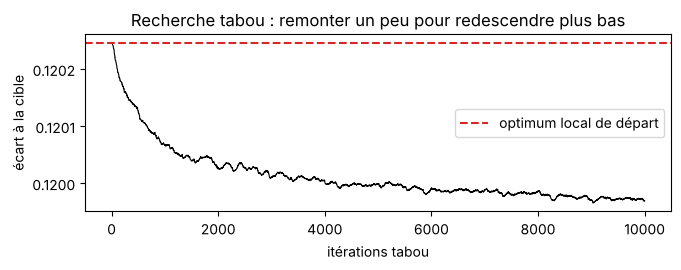

In [11]:
r_rec = resoudre(pb, "recuit")
r_tab = resoudre(pb, "tabou")
for r in (r_rec, r_tab):
    print(f"{r.nom:<7} : écart {np.sqrt(r.cout):.4f}, {r.n_cordes} cordes, {r.duree_s:.1f} s, "
          f"gain sur la recherche locale {100 * (1 - r.cout / r_loc.cout):.2f} %")  # fmt: skip

figure, axe = plt.subplots(figsize=(7, 2.8))
debut_tabou = len(r_loc.journal)
axe.plot(np.sqrt(r_tab.couts[debut_tabou:]), color="black", linewidth=0.8)
axe.axhline(np.sqrt(r_loc.cout), color="tab:red", linestyle="--", label="optimum local de départ")
axe.set_xlabel("itérations tabou")
axe.set_ylabel("écart à la cible")
axe.set_title("Recherche tabou : remonter un peu pour redescendre plus bas")
axe.legend()
tracer(figure)

Les deux grattent encore un demi pour cent, au prix de plusieurs secondes. La courbe du tabou
montre le mécanisme : l'objectif remonte d'abord (on quitte le creux), puis redescend sous son
niveau de départ. **Succès mitigé** : c'est mesurable, pas visible à l'œil.

Trois méthodes très différentes qui butent au même niveau, cela pose une question : sont-elles
toutes coincées au même endroit par maladresse, ou est-on près de ce que le fil permet ?

### 5.6 Une borne : la relaxation continue

Pour le savoir, on triche. Au lieu de décider pour chaque corde « posée ou non », on lui donne
une **intensité** entre 0 et 1, comme si l'on disposait de fils d'opacité réglable. Le problème
devient lisse, et se résout par une méthode de gradient (L-BFGS) sur les 26 520 intensités à la
fois. Cette solution « relâchée » n'est pas réalisable, mais elle indique jusqu'où l'on pourrait
descendre si les fils n'étaient pas en tout-ou-rien.

solution relâchée (irréalisable) : écart 0.1093 ; 7190 cordes ont une intensité intermédiaire
arrondi brut au plus proche      : écart 0.1832 (1581 cordes)
arrondi puis recherche locale    : écart 0.1201 (2564 cordes)
meilleure solution réelle connue : écart 0.1200


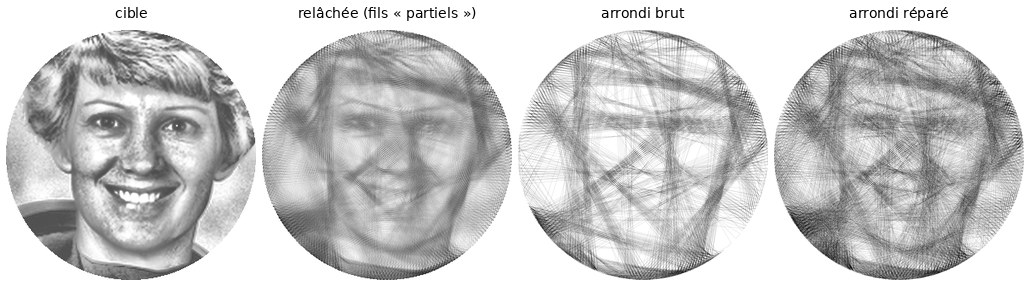

In [12]:
r_brut = solveurs.relaxation(pb, reparer=False)
r_rel = resoudre(pb, "relaxation")
infos = r_rel.infos
intensites = infos["intensites"].astype(np.float64)
image_relachee = np.exp(log_visible @ intensites / GAMMA).reshape(forme)

print(f"solution relâchée (irréalisable) : écart {np.sqrt(infos['cout_relache']):.4f} ; "
      f"{infos['cordes_fractionnaires']} cordes ont une intensité intermédiaire")  # fmt: skip
print(f"arrondi brut au plus proche      : écart {np.sqrt(infos['cout_arrondi']):.4f} "
      f"({infos['cordes_arrondi']} cordes)")  # fmt: skip
print(
    f"arrondi puis recherche locale    : écart {np.sqrt(r_rel.cout):.4f} ({r_rel.n_cordes} cordes)"
)
print(f"meilleure solution réelle connue : écart {np.sqrt(min(r_rec.cout, r_tab.cout)):.4f}")
montrer(
    [cible, np.where(GEO.masque, image_relachee, 1.0), simuler(TOILE, r_brut.sequence),
     simuler(TOILE, r_rel.sequence)],
    ["cible", "relâchée (fils « partiels »)", "arrondi brut", "arrondi réparé"],
)  # fmt: skip

Trois enseignements.

**Échec n° 5 : l'arrondi.** La solution relâchée est belle, mais elle répartit le travail sur
des milliers de cordes d'intensité intermédiaire. Les arrondir chacune au plus proche jette
plus d'un tiers de l'encre : l'image arrondie est bien pire que celle d'un simple glouton. Il
faut une recherche locale derrière pour réparer, et l'on retombe alors… au niveau des autres
méthodes.

**L'image relâchée est elle-même floue.** On y reconnaît le visage, mais même avec des fils
d'opacité réglable, 240 clous ne savent pas rendre cette image nettement. Le flou n'est pas la faute du solveur : il est dans la
géométrie. On ne peut assombrir un point qu'en traçant des droites qui traversent toute la toile.

**Les solveurs sont près du plafond.** La meilleure solution réelle est à une dizaine de pour
cent de la solution relâchée (en écart à la cible). C'est un majorant de ce qu'il reste à gagner en
changeant de méthode — et une partie de cet écart est le prix du tout-ou-rien, qu'aucune méthode
ne récupérera. (Réserve : l'objectif relâché n'est pas convexe partout, la valeur relâchée
n'est donc pas une borne *prouvée* — c'est une bonne indication.)

## 6. Le banc d'essai

Les sept méthodes, sur les quatre images, avec les mêmes réglages. Pour chaque passage :
l'objectif atteint (« écart modèle », ce que le solveur optimise), les notes du juge sur la
pièce simulée, le nombre de cordes, la longueur de fil et le temps de calcul.

In [13]:
debut = time.perf_counter()
MESURES, RESULTATS = banc.lancer(PROBLEMES, garder_resultats=True)
print(f"banc complet : {time.perf_counter() - debut:.0f} s")
dire(banc.tableau_mesures(MESURES))

banc complet : 79 s


| problème | solveur | écart modèle | EQM | EQM floue | SSIM | cordes | fil (m) | durée (s) |
|---|---|---:|---:|---:|---:|---:|---:|---:|
| portrait | recherche_locale | 0.1202 | 0.1261 | 0.0722 | 0.324 | 2557 | 918 | 0.6 |
| portrait | recuit | 0.1200 | 0.1259 | 0.0722 | 0.327 | 2569 | 919 | 5.0 |
| portrait | tabou | 0.1200 | 0.1259 | 0.0722 | 0.327 | 2568 | 919 | 1.8 |
| portrait | relaxation | 0.1201 | 0.1262 | 0.0723 | 0.327 | 2564 | 918 | 7.3 |
| portrait | glouton_global | 0.1206 | 0.1264 | 0.0723 | 0.321 | 2558 | 920 | 0.5 |
| portrait | glouton_sequentiel | 0.1213 | 0.1268 | 0.0728 | 0.318 | 2587 | 930 | 0.4 |
| portrait | tri_naif | 0.2877 | 0.2901 | 0.2624 | 0.294 | 2702 | 533 | 0.4 |
| chat | recherche_locale | 0.1029 | 0.1080 | 0.0563 | 0.296 | 2456 | 830 | 0.6 |
| chat | recuit | 0.1025 | 0.1078 | 0.0565 | 0.300 | 2467 | 831 | 4.6 |
| chat | tabou | 0.1026 | 0.1078 | 0.0564 | 0.299 | 2461 | 831 | 1.7 |
| chat | relaxation | 0.1027 | 0.1082 | 0.0564 | 0.299 | 2463 | 831 | 8.4 |
| chat | glouton_global | 0.1038 | 0.1085 | 0.0567 | 0.292 | 2449 | 833 | 0.4 |
| chat | glouton_sequentiel | 0.1050 | 0.1093 | 0.0573 | 0.289 | 2479 | 842 | 0.5 |
| chat | tri_naif | 0.3031 | 0.3064 | 0.2862 | 0.372 | 2410 | 421 | 0.3 |
| arbre | recherche_locale | 0.1044 | 0.1075 | 0.0323 | 0.416 | 2505 | 830 | 0.6 |
| arbre | recuit | 0.1040 | 0.1072 | 0.0325 | 0.421 | 2513 | 831 | 5.0 |
| arbre | tabou | 0.1041 | 0.1073 | 0.0325 | 0.420 | 2512 | 831 | 1.3 |
| arbre | relaxation | 0.1041 | 0.1074 | 0.0324 | 0.420 | 2508 | 830 | 11.9 |
| arbre | glouton_global | 0.1045 | 0.1077 | 0.0323 | 0.416 | 2506 | 831 | 0.4 |
| arbre | glouton_sequentiel | 0.1051 | 0.1082 | 0.0326 | 0.414 | 2531 | 837 | 0.5 |
| arbre | tri_naif | 0.3136 | 0.3149 | 0.2928 | 0.190 | 2436 | 335 | 0.4 |
| elephant | recherche_locale | 0.1301 | 0.1325 | 0.0643 | 0.302 | 1486 | 624 | 0.5 |
| elephant | recuit | 0.1300 | 0.1324 | 0.0643 | 0.301 | 1492 | 625 | 3.3 |
| elephant | tabou | 0.1300 | 0.1324 | 0.0643 | 0.303 | 1489 | 624 | 2.0 |
| elephant | relaxation | 0.1301 | 0.1325 | 0.0641 | 0.303 | 1488 | 624 | 5.2 |
| elephant | glouton_global | 0.1302 | 0.1326 | 0.0643 | 0.302 | 1487 | 625 | 0.3 |
| elephant | glouton_sequentiel | 0.1308 | 0.1332 | 0.0645 | 0.299 | 1510 | 633 | 0.3 |
| elephant | tri_naif | 0.1745 | 0.1820 | 0.1269 | 0.392 | 1856 | 694 | 0.5 |

**Classement**, moyenné sur les quatre images (retard sur le meilleur objectif obtenu) :

| solveur | retard sur le meilleur objectif | EQM floue | SSIM | cordes | durée (s) |
|---|---:|---:|---:|---:|---:|
| recuit | +0.01 % | 0.0563 | 0.337 | 2260 | 4.5 |
| tabou | +0.05 % | 0.0563 | 0.337 | 2258 | 1.7 |
| relaxation | +0.27 % | 0.0563 | 0.337 | 2256 | 8.2 |
| recherche_locale | +0.53 % | 0.0562 | 0.335 | 2251 | 0.6 |
| glouton_global | +1.25 % | 0.0564 | 0.333 | 2250 | 0.4 |
| glouton_sequentiel | +2.61 % | 0.0568 | 0.330 | 2277 | 0.5 |
| tri_naif | +534.59 % | 0.2421 | 0.312 | 2351 | 0.4 |

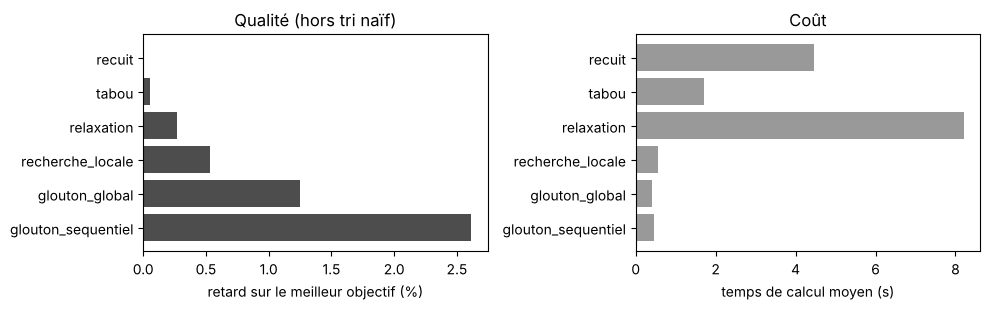

In [14]:
dire("**Classement**, moyenné sur les quatre images (retard sur le meilleur objectif obtenu) :\n\n"
     + banc.tableau_classement(MESURES))  # fmt: skip

classes = [ligne for ligne in banc.classement(MESURES) if ligne["solveur"] != "tri_naif"]
figure, (gauche, droite) = plt.subplots(1, 2, figsize=(10, 3.2))
noms = [ligne["solveur"] for ligne in classes]
gauche.barh(noms[::-1], [ligne["retard_pct"] for ligne in classes][::-1], color="0.3")
gauche.set_xlabel("retard sur le meilleur objectif (%)")
gauche.set_title("Qualité (hors tri naïf)")
droite.barh(noms[::-1], [ligne["duree_s"] for ligne in classes][::-1], color="0.6")
droite.set_xlabel("temps de calcul moyen (s)")
droite.set_title("Coût")
tracer(figure)

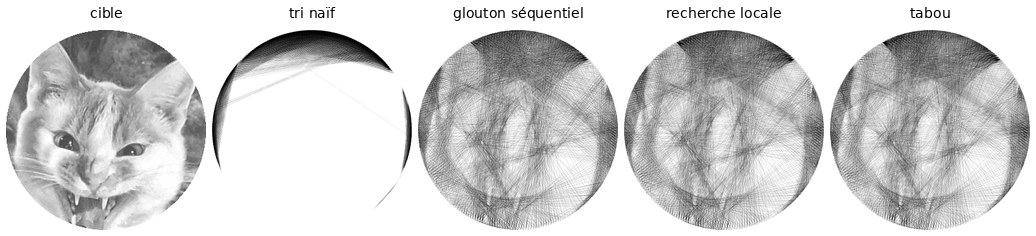

In [15]:
montrer(
    [CIBLES["chat"]] + [simuler(TOILE, RESULTATS[("chat", nom)].sequence)
                        for nom in ("tri_naif", "glouton_sequentiel", "recherche_locale", "tabou")],
    ["cible", "tri naïf", "glouton séquentiel", "recherche locale", "tabou"],
    taille=200,
)  # fmt: skip

**Ce que dit le banc.**

- Le **tri naïf** est hors course (c'est son rôle de témoin).
- Les six autres méthodes tiennent **à moins de trois pour cent** les unes des autres sur
  l'objectif,
  et leurs notes au juge sont indiscernables. Sur les images, il faut les superposer pour voir
  une différence.
- **Une note seule peut mentir.** Sur l'éléphant, c'est le tri naïf qui obtient la meilleure
  SSIM, alors que son rendu est de loin le plus mauvais : il laisse intactes de grandes plages
  blanches, que cette note récompense. D'où trois notes, et les images à côté.
- **Tabou et recuit** obtiennent les meilleurs objectifs, pour quelques secondes de calcul.
- La **recherche locale** fait presque aussi bien en moins d'une seconde : c'est le meilleur
  rapport qualité/temps, d'où son statut de méthode par défaut.
- Le **glouton séquentiel**, dernier des méthodes sérieuses, garde un avantage pratique : sa
  séquence est un fil continu « naturel », presque sans pas de bord.

La conclusion est celle de la section 5.6 : **la méthode de résolution n'est pas le facteur
limitant**. Pour améliorer le rendu, il faut regarder ailleurs.

## 7. Ce qui change vraiment le résultat (et ce qui ne change rien)

### 7.1 La mise en tons de la cible — le levier principal

Jusqu'ici les cibles étaient déjà « mises en tons ». Voici ce qu'on obtient sans, et pourquoi
chaque étape a été ajoutée. Quatre traitements du même portrait, résolus de la même façon :

- **brut** : l'image telle quelle ;
- **plancher de noir** (`noir=0.3`) : les tons sont comprimés pour que le noir de l'image
  devienne un gris foncé ;
- **contraste local** (`contraste="local"`) : une égalisation adaptative (CLAHE) qui renforce le
  relief partout, en plus du plancher de noir. Sa force se règle avec `relief` : faible (0,01)
  ou forte (0,03).

brut             : 4810 cordes, 1464 m de fil, SSIM 0.31


plancher de noir : 2317 cordes, 733 m de fil, SSIM 0.31


relief 0,01      : 2404 cordes, 825 m de fil, SSIM 0.32


relief 0,03      : 2557 cordes, 918 m de fil, SSIM 0.32


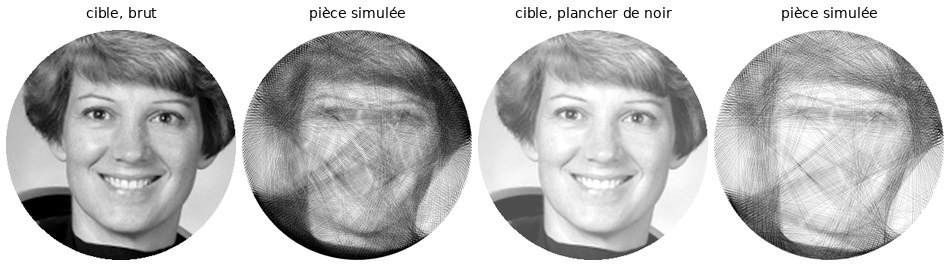

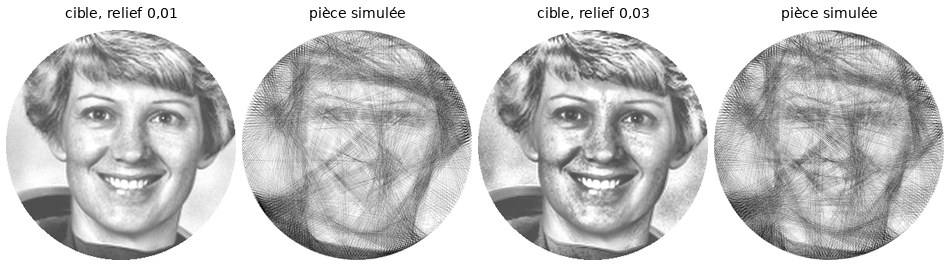

In [16]:
image_portrait, cadrage_portrait = SOURCES["portrait"][0], {"zoom": 1.55, "decalage": (-0.01, 0.02)}
variantes = {
    "brut": {"contraste": "aucun", "noir": 0.0},
    "plancher de noir": {"contraste": "auto", "noir": 0.3},
    "relief 0,01": {"contraste": "local", "relief": 0.01, "noir": 0.3},
    "relief 0,03": {"contraste": "local", "relief": 0.03, "noir": 0.3},
}


def essayer_tons(image, cadrage, variantes):
    """Résout une même image sous plusieurs mises en tons ; affiche cibles et pièces simulées."""
    planches, titres = [], []
    for nom, reglages in variantes.items():
        c = preparer_cible(image, TOILE.cote, **cadrage, **reglages)
        r = resoudre(Probleme(GEO, c))
        notes = comparer(c, rendu_physique(TOILE, r.sequence))
        print(f"{nom:<17}: {r.n_cordes} cordes, {longueur_fil_m(TOILE, r.sequence):.0f} m de fil, "
              f"SSIM {notes.ssim:.2f}")  # fmt: skip
        planches += [c, simuler(TOILE, r.sequence)]
        titres += [f"cible, {nom}", "pièce simulée"]
    for debut in range(0, len(planches), 4):
        montrer(planches[debut : debut + 4], titres[debut : debut + 4], taille=230)


essayer_tons(image_portrait, cadrage_portrait, variantes)

**Échec n° 6 : demander l'image telle quelle.** Le rendu brut consomme deux fois plus de fil que
les autres pour le résultat le moins lisible : des masses sombres, une bande à hauteur des
yeux, guère de visage. Deux raisons, toutes deux liées à ce qu'une toile de fils sait faire :

- **Le noir profond est hors de prix.** Atteindre un noir d'image demande une cinquantaine de
  passages par pixel, et chacun de ces fils traverse *toute* la toile : il voile le reste de
  l'image sur son trajet. Viser un gris foncé plutôt qu'un noir libère du fil pour les détails,
  et en économise beaucoup.
- **Les nuances douces sont sous le grain.** Entre une joue et l'ombre du nez, l'écart de ton
  vaut deux ou trois fils. C'est moins que le bruit du tramage : la nuance disparaît. Le
  contraste local l'amplifie jusqu'à ce qu'elle « pèse » assez de fils pour exister.

Avec le plancher de noir seul, la pièce s'allège mais reste sans traits. C'est avec un relief
fort que les yeux, le nez et le sourire se dessinent. La mise en tons fait le visage, pas le
solveur.

**Mais il n'y a pas de réglage universel.** La même expérience sur le chat :

sans relief      : 2326 cordes, 753 m de fil, SSIM 0.28


relief 0,01      : 2456 cordes, 830 m de fil, SSIM 0.30


relief 0,03      : 2530 cordes, 890 m de fil, SSIM 0.32


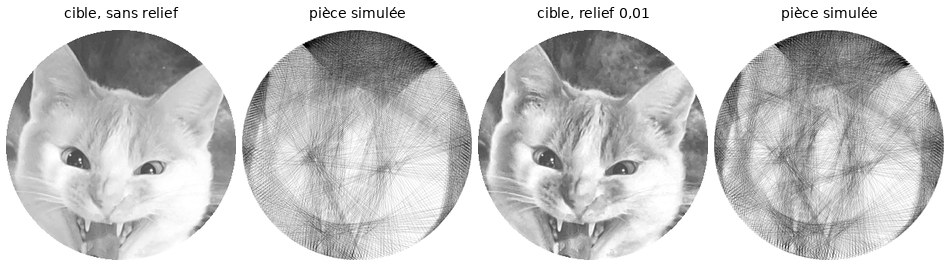

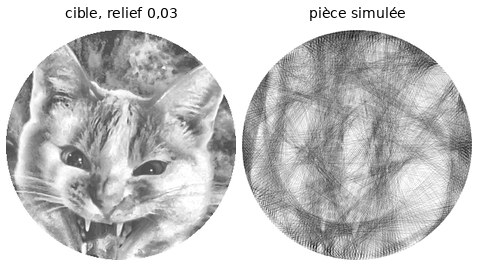

In [17]:
essayer_tons(
    SOURCES["chat"][0],
    {"zoom": 1.25, "decalage": (0.0, -0.08)},
    {
        "sans relief": {"contraste": "auto", "noir": 0.3},
        "relief 0,01": {"contraste": "local", "relief": 0.01, "noir": 0.3},
        "relief 0,03": {"contraste": "local", "relief": 0.03, "noir": 0.3},
    },
)

Ici c'est l'inverse. La photo du chat est déjà pleine de textures — pelage, feuillage du fond.
Un relief fort les amplifie toutes : la cible devient un fouillis de détails que la toile ne
peut pas rendre, et le sujet s'y noie. Sans relief, ou avec un relief faible, on lit mieux la
tête claire, les oreilles et les deux yeux.

D'où un réglage `relief` par image, et un défaut intermédiaire (0,02) : **fort pour un visage
lisse, faible pour une image déjà chargée**. Le chat reste, quoi qu'on fasse, un sujet moins
docile que le portrait : un pelage clair sur fond sombre offre peu de formes franches.

### 7.2 Le cadrage

La finesse d'une toile est fixée par ses clous : un détail plus petit que quelques millimètres
n'existe pas. Autant donc que le sujet **remplisse le disque**. Le même portrait, en plan large
puis serré sur le visage :

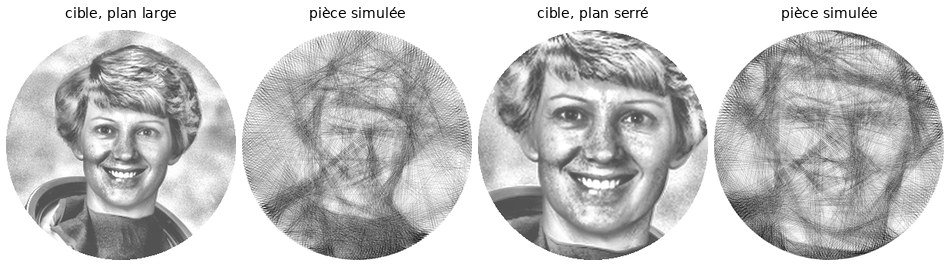

In [18]:
planches, titres = [], []
for nom, cadrage in [("plan large", {}), ("plan serré", cadrage_portrait)]:
    c = preparer_cible(image_portrait, TOILE.cote, relief=0.03, **cadrage)
    r = resoudre(Probleme(GEO, c))
    planches += [c, simuler(TOILE, r.sequence)]
    titres += [f"cible, {nom}", "pièce simulée"]
montrer(planches, titres, taille=230)

En plan large, on reconnaît une silhouette — une coiffure, des épaules — mais les yeux et la
bouche, qui ne font que quelques millimètres sur la toile, se réduisent à des traits. Serré,
le visage a la place d'exister. Les réglages `zoom` et `decalage` servent à cela.

### 7.3 Les leviers physiques : clous, fil, résolution

Pour comparer des toiles différentes, toutes les pièces sont simulées puis notées à la même
taille (300 px), contre la même cible.

| toile | cordes | fil (m) | EQM floue | SSIM |
|---|---:|---:|---:|---:|
| référence : 240 clous, fil 0,2 mm, 300 px | 2557 | 918 | 0.072 | 0.324 |
| 160 clous | 2511 | 894 | 0.080 | 0.273 |
| 200 clous | 2560 | 910 | 0.074 | 0.305 |
| 300 clous | 2563 | 923 | 0.070 | 0.340 |
| fil de 0,15 mm | 3415 | 1228 | 0.074 | 0.362 |
| fil de 0,3 mm | 1686 | 603 | 0.071 | 0.264 |
| fil de 0,5 mm | 970 | 346 | 0.071 | 0.192 |
| grille de 200 px | 2529 | 916 | 0.073 | 0.304 |
| grille de 400 px | 2547 | 906 | 0.073 | 0.315 |

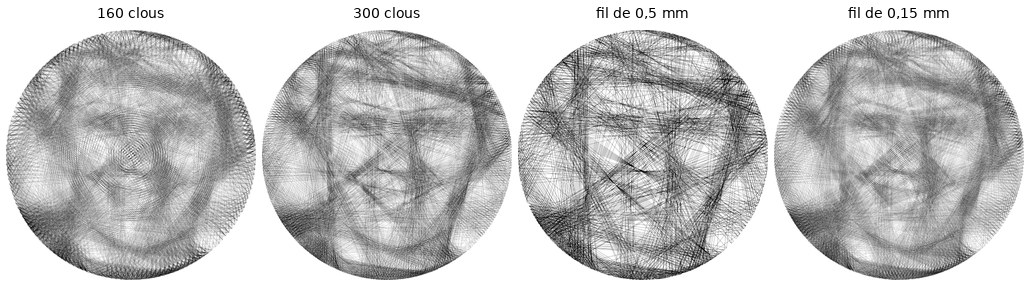

In [19]:
reference = CIBLES["portrait"]
essais = [
    ("référence : 240 clous, fil 0,2 mm, 300 px", TOILE),
    ("160 clous", Toile(n_clous=160)),
    ("200 clous", Toile(n_clous=200)),
    ("300 clous", Toile(n_clous=300)),
    ("fil de 0,15 mm", Toile(epaisseur_fil_mm=0.15)),
    ("fil de 0,3 mm", Toile(epaisseur_fil_mm=0.3)),
    ("fil de 0,5 mm", Toile(epaisseur_fil_mm=0.5)),
    ("grille de 200 px", Toile(cote=200)),
    ("grille de 400 px", Toile(cote=400)),
]
lignes = ["| toile | cordes | fil (m) | EQM floue | SSIM |", "|---|---:|---:|---:|---:|"]
vues = {}
for nom, toile in essais:
    c = preparer_cible(image_portrait, toile.cote, relief=0.03, **cadrage_portrait)
    r = resoudre(Probleme(geometrie(toile), c))
    notes = comparer(reference, rendu_physique(toile, r.sequence, taille=300))
    lignes.append(f"| {nom} | {r.n_cordes} | {longueur_fil_m(toile, r.sequence):.0f} | "
                  f"{notes.eqm_floue:.3f} | {notes.ssim:.3f} |")  # fmt: skip
    vues[nom] = simuler(toile, r.sequence)
dire("\n".join(lignes))
montrer(
    [vues["160 clous"], vues["300 clous"], vues["fil de 0,5 mm"], vues["fil de 0,15 mm"]],
    ["160 clous", "300 clous", "fil de 0,5 mm", "fil de 0,15 mm"],
)

- **Plus de clous, c'est mieux**, régulièrement : de 160 à 300 clous la structure (SSIM) gagne
  à chaque palier. Le défaut de 240 est un compromis entre la finesse et le nombre de trous à
  percer ; 300 reste faisable à la main.
- **Un fil plus fin, c'est mieux aussi** — et plus long. Un fil fin dépose l'encre par petites
  touches : il en faut davantage, donc les tons sont plus finement dosés. Un gros fil (0,5 mm)
  fait une pièce rapide et grossière. C'est le vrai curseur « qualité contre heures de travail ».
- **La résolution de calcul n'apporte rien au-delà de 300 px** : la limite vient des clous et du
  fil, pas de la grille. Inutile de payer plus de mémoire et de temps.

### 7.4 Un objectif « vu de loin » — test sans effet

Une idée naturelle : l'œil ne voit pas les pixels mais des zones. On peut donc comparer la toile
et la cible à plusieurs échelles à la fois (pixels, blocs de 2 × 2, blocs de 4 × 4), pour que
le grain d'un fil isolé soit moins pénalisé. Le moteur le permet sans modification : pour lui,
une cellule grossière n'est qu'un « pixel » de plus.

| objectif | cordes | EQM | EQM floue | SSIM |
|---|---:|---:|---:|---:|
| pixel à pixel | 2557 | 0.126 | 0.072 | 0.324 |
| échelles 1, 2 et 4 | 2568 | 0.127 | 0.071 | 0.314 |

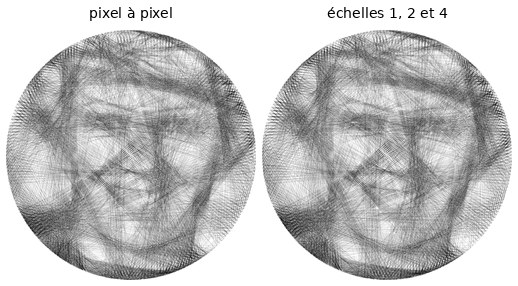

In [20]:
c = CIBLES["portrait"]
lignes = ["| objectif | cordes | EQM | EQM floue | SSIM |", "|---|---:|---:|---:|---:|"]
vues = []
for nom, echelles in [("pixel à pixel", (1,)), ("échelles 1, 2 et 4", (1, 2, 4))]:
    r = resoudre(Probleme(geometrie(TOILE, echelles), c))
    notes = comparer(c, rendu_physique(TOILE, r.sequence))
    lignes.append(f"| {nom} | {r.n_cordes} | {notes.eqm:.3f} | {notes.eqm_floue:.3f} | "
                  f"{notes.ssim:.3f} |")  # fmt: skip
    vues.append(simuler(TOILE, r.sequence))
dire("\n".join(lignes))
montrer(vues, ["pixel à pixel", "échelles 1, 2 et 4"])

**Échec n° 7, utile.** Les deux pièces sont indiscernables à l'œil. Les notes bougent à peine,
et pas dans le même sens : l'écart flou gagne un millième, la SSIM en perd une dizaine. Rien
qui ressemble à un progrès. L'objectif pixel à pixel se comportait déjà comme un objectif « vu
de loin », parce qu'un pixel de travail est déjà huit fois plus gros que le fil. La possibilité
reste dans le code (`geometrie(toile, echelles=(1, 2, 4))`) mais n'est pas activée par défaut :
elle double presque la mémoire pour rien.

### 7.5 Le budget : combien de cordes faut-il vraiment ?

Une pièce complète représente 2 500 cordes et près d'un kilomètre de fil : une dizaine d'heures
de montage. Peut-on s'arrêter avant ? `cordes_max` plafonne le nombre de cordes.

  600 cordes :  273 m de fil, ~3 h de montage, EQM floue 0.243, SSIM 0.25


 1200 cordes :  515 m de fil, ~5 h de montage, EQM floue 0.154, SSIM 0.27


 1800 cordes :  724 m de fil, ~8 h de montage, EQM floue 0.094, SSIM 0.30


 2557 cordes :  918 m de fil, ~11 h de montage, EQM floue 0.072, SSIM 0.32


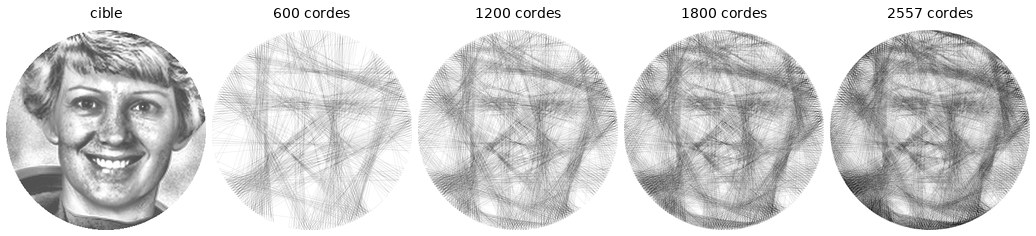

In [21]:
c = CIBLES["portrait"]
planches, titres = [c], ["cible"]
for plafond in (600, 1200, 1800, None):
    r = resoudre(PROBLEMES["portrait"], cordes_max=plafond)
    notes = comparer(c, rendu_physique(TOILE, r.sequence))
    heures = (len(r.sequence) - 1) * 15 / 3600
    print(f"{r.n_cordes:>5} cordes : {longueur_fil_m(TOILE, r.sequence):>4.0f} m de fil, "
          f"~{heures:.0f} h de montage, EQM floue {notes.eqm_floue:.3f}, SSIM {notes.ssim:.2f}")  # fmt: skip
    planches.append(simuler(TOILE, r.sequence))
    titres.append(f"{r.n_cordes} cordes")
montrer(planches, titres, taille=200)

Le visage se devine à 1 200 cordes et il est en place à 1 800, aux deux tiers du travail ; les
dernières centaines apportent de la densité et du contraste plus que de l'information. C'est
cohérent avec la courbe de convergence de la section 5.2. Pour un premier essai, plafonner
autour de 1 800 est raisonnable.

## 8. À vous : calculer une pièce

Tout ce qui précède est emballé dans une fonction, `creer`. Modifiez les réglages de la cellule
ci-dessous, exécutez-la, regardez le résultat, recommencez. Quand l'aperçu vous convient, la
cellule suivante écrit les fichiers nécessaires au montage.

Dans l'ordre où il vaut la peine d'y toucher :

1. **`zoom` et `decalage`** — que le sujet remplisse le disque.
2. **`relief`** — 0,03 pour un visage, 0,01 pour une photo déjà chargée de textures.
   `contraste="auto"` le coupe (dessin, image déjà très contrastée) ; `"aucun"` ne touche à rien.
3. **`noir`** — plus haut (0,4) : pièce plus légère, moins de fil. Plus bas (0,2) : plus dense.
4. **`gamma`** — au-dessus de 1, assombrit les tons moyens (plus de fil).
5. **La toile** — vos vraies dimensions, votre vrai fil, votre nombre de clous.
6. **`cordes_max`** — pour borner le temps de montage.

Toile de 500 mm, 240 clous, fil de 0.2 mm.
Méthode : recherche_locale (0.6 s de calcul, arrêt : convergence).
2557 cordes, 2661 passages dont 104 le long du bord.
Environ 918 m de fil et 11 h de montage (à 15 s le passage).
Fidélité simulée : EQM floue 0.072, SSIM 0.32.


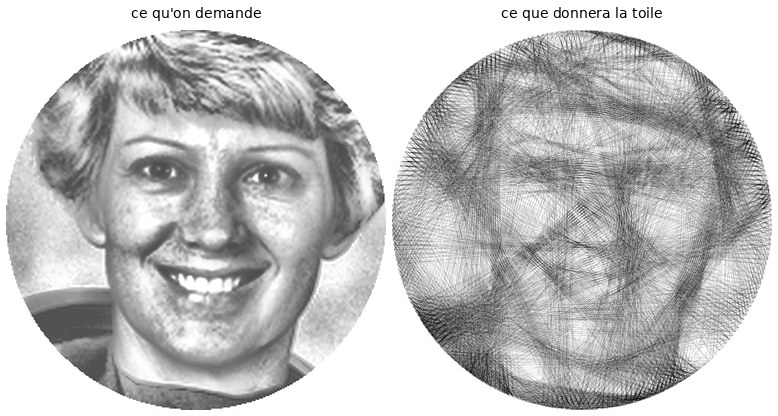

In [22]:
IMAGE = IMAGES / "portrait.png"  # ← votre image

MA_TOILE = Toile(
    diametre_mm=500,  # diamètre du cercle des clous
    n_clous=240,  # régulièrement espacés ; clou 0 en haut, sens horaire
    epaisseur_fil_mm=0.2,  # le vrai diamètre de votre fil
)

oeuvre = creer(
    IMAGE,
    MA_TOILE,
    solveur="recherche_locale",  # voir la liste ci-dessous
    zoom=1.55,  # > 1 : on se rapproche du sujet
    decalage=(-0.01, 0.02),  # (vers la droite, vers le bas), en fraction de l'image
    contraste="local",
    relief=0.03,
    noir=0.3,
    gamma=1.0,
    cordes_max=None,  # par exemple 1500 pour une pièce plus rapide à monter
)

print(oeuvre.resume())
montrer(
    [oeuvre.cible, oeuvre.apercu(600)], ["ce qu'on demande", "ce que donnera la toile"], taille=380
)

In [23]:
print("Méthodes disponibles (la recommandée est marquée d'une flèche) :\n")
for fiche in SOLVEURS.values():
    print(f"  {fiche.nom:<19} {fiche.etoiles}  {fiche.resume}{'  ←' if fiche.recommande else ''}")

Méthodes disponibles (la recommandée est marquée d'une flèche) :

  recherche_locale    ★★★  Glouton avec remords : pose ou retire la meilleure corde jusqu'à l'optimum local.  ←
  recuit              ★★★  Recuit simulé partant de la recherche locale : le dernier pour-cent, en plus lent.
  tabou               ★★★  Recherche tabou partant de la recherche locale : comparable au recuit, déterministe.
  relaxation          ★★★  Optimisation continue puis arrondi réparé ; fournit aussi une borne de référence.
  glouton_global      ★★☆  Glouton sans retour en arrière, toutes cordes confondues.
  glouton_sequentiel  ★★☆  Glouton historique : le fil repart du dernier clou. Séquence sans parcours eulérien.
  tri_naif            ☆☆☆  Témoin négatif : les cordes les plus sombres, sans tenir compte les unes des autres.


### Les livrables

`enregistrer` écrit cinq fichiers :

| fichier | usage |
|---|---|
| `sequence.txt` | la suite de clous, dix par ligne avec le rang des passages — à imprimer |
| `guide.html` | la même, pas à pas : un gros numéro, lecture à voix haute, avance automatique, reprise là où l'on s'est arrêté. À ouvrir sur un téléphone posé près de la toile |
| `piece.svg` | le tracé à l'échelle 1, avec la position des clous : imprimé sans mise à l'échelle, c'est le gabarit de perçage |
| `rendu.png` | la simulation de la pièce |
| `comparaison.png` | la cible à côté de la simulation |

In [24]:
chemins = oeuvre.enregistrer(RACINE / "sortie")
for nom, chemin in chemins.items():
    print(f"{nom:<12} {chemin.relative_to(RACINE)}")
print()
print("\n".join(texte_sequence(oeuvre.toile, oeuvre.sequence).splitlines()[:14]))
print("…")

rendu        sortie/rendu.png
comparaison  sortie/comparaison.png
sequence     sortie/sequence.txt
guide        sortie/guide.html
svg          sortie/piece.svg

STRING ART — séquence de montage

Toile ronde de 500 mm, 240 clous régulièrement espacés, fil de 0.2 mm.
Clou 0 en haut ; les numéros croissent dans le sens des aiguilles d'une montre.
2661 passages (104 le long du bord), environ 918 m de fil (prévoir 10 % de marge).
Deux numéros consécutifs (ex. 41 puis 42) : longer le bord jusqu'au clou voisin.

Départ : nouer le fil au clou 181.

   1-10   | 167 168 169 170 171 172 173 216 215 214
  11-20   | 213 227 168 234 224 140 139 138 137 136
  21-30   | 222 209 210 220 202 203 219 209 178 177
  31-40   | 176 175 234 142 143 144 239   0 181 153
  41-50   | 154 155 156 227 166 167 233 232 167 228
…


La même chose en ligne de commande :

```bash
uv run stringart-claude creer images/portrait.png -o sortie
uv run stringart-claude creer photo.jpg --clous 300 --fil 0.15 --zoom 1.4 --cordes-max 2000
uv run stringart-claude algos       # les méthodes disponibles
uv run stringart-claude banc images/*.png   # refaire le banc d'essai sur ses images
```

## 9. Bilan

| # | Ce qui a été essayé | Verdict | Ce qu'on en retient |
|---|---|---|---|
| 1 | Juger avec les traits de Pillow | ❌ échec | Les traits fins n'ont pas la même largeur dans toutes les directions. Vérifier le juge sur un cas connu avant de s'en servir. |
| 2 | Modèle du fil par addition écrêtée | ❌ échec | Compte deux fois les chevauchements : prédit une toile bien trop noire. |
| 3 | Modèle par produit des parts visibles | ✅ succès | Colle à la simulation sans biais ; rend les retraits aussi bon marché que les poses. |
| 4 | Comparer la lumière de la toile aux valeurs de l'image | ❌ échec | La pièce sort délavée. La conversion perceptuelle (gamma 2,2) se loge dans la matrice, gratuitement. |
| 5 | Tenir à jour le gain de toutes les cordes | ✅ succès | Un coup coûte une fraction de milliseconde ; une résolution, une seconde. |
| 6 | Tri naïf des cordes les plus sombres | ❌ échec | Des faisceaux sans rapport avec l'image : une corde ne vaut que par rapport aux autres. |
| 7 | Glouton séquentiel (fil continu) | ✅ succès | Simple, rapide, à moins de trois pour cent du meilleur. |
| 8 | Glouton global + chemin eulérien | ✅ succès | La contrainte du fil continu coûte environ un pour cent ; l'ordre de pose est un problème séparé. |
| 9 | Recherche locale (poses et retraits) | ✅ succès | Le meilleur rapport qualité/temps : méthode par défaut. |
| 10 | Recuit simulé, recherche tabou | 🟡 mitigé | Encore un demi pour cent, en plusieurs secondes. Invisible à l'œil. |
| 11 | Relaxation continue + arrondi | ❌ puis ✅ | L'arrondi brut détruit la solution ; réparé, il rejoint les autres. Sert surtout de borne : les solveurs sont près du plafond. |
| 12 | Objectif multi-échelle | ❌ sans effet | Le pixel de travail est déjà bien plus gros que le fil. |
| 13 | Demander l'image telle quelle | ❌ échec | Noirs hors de prix, nuances sous le grain. |
| 14 | Plancher de noir + contraste local | ✅ succès | **Le levier principal** : c'est lui qui fait apparaître un visage. Sa force se règle image par image. |
| 15 | Plus de clous, fil plus fin | ✅ succès | Gain régulier, payé en heures de montage. |
| 16 | Grille de calcul plus fine | ❌ sans effet | La limite est physique, pas numérique. |

**L'idée à garder.** Sur ce problème, l'effort d'optimisation plafonne vite : six méthodes très
différentes arrivent au même point, et une borne indépendante confirme qu'il n'y a plus grand-chose
au-dessus. Ce qui fait la différence est en amont — *ce qu'on demande à la toile* (cadrage,
tons) — et dans la physique — *de quoi elle est faite* (clous, fil). Et rien de tout cela n'aurait
pu être établi sans un modèle du fil validé contre une simulation indépendante.

**Limites connues.**

- Les sujets clairs à petits détails sombres (le chat détouré, l'éléphant) restent difficiles :
  on ne peut assombrir un point qu'en traversant toute la toile.
- Les clous sont des points : leur diamètre, et le côté par lequel le fil les contourne, ne sont
  pas modélisés.
- Le fil est supposé parfaitement noir et mat, la toile parfaitement blanche.
- Les notes du juge suivent l'œil dans les grandes lignes, pas dans le détail : entre deux
  rendus proches, c'est l'œil qui tranche.

**Pistes.** Fil de couleur ou plusieurs fils ; toiles non circulaires ; pondération par zones
d'intérêt (le moteur accepte déjà une carte de poids) ; une interface graphique avec le rendu
qui se construit en direct, pour laquelle le journal des solveurs et le crochet `suivi` sont
déjà en place.